# Construir y validar un plan minero condicionado por el estado

**Pregunta:** ¿Cómo elige una política entre los bloques que siguen siendo factibles en cada decisión?

**Nivel:** Un método aplicado y análisis de evidencia con límites explícitos de afirmación.

## Objetivos

Esta lección guiada sigue un grafo sintético pequeño a través del contrato de planificación condicionado por el estado. Generarás una instancia repetible, inspeccionarás variables de nodo con nombre, ajustarás un normalizador solo con datos de entrenamiento, distinguirás la disponibilidad por precedencia de la factibilidad completa de recursos, avanzarás una política transparente y validarás las asignaciones exportadas desde la instancia original. El ejercicio se concentra en decisiones que pueden auditarse estado por estado. No entrena una red neuronal, no estima el desempeño en yacimientos desconocidos ni representa una mina en operación. Trata los valores generados como datos sintéticos para desarrollar el método y conserva las unidades declaradas en cada comparación.

## Preparación

Ejecuta desde la raíz del repositorio con las dependencias fijadas del cuaderno. La lección importa el generador de grafos y las primitivas de planificación del producto; no vuelve a definir esas funciones. No requiere acceso a la red, pesos del modelo, datos privados ni trabajos de entrenamiento. Una semilla y versión de generador fijas hacen reproducible la entrada. Las versiones de paquetes importan porque cambios del generador, solucionador o biblioteca numérica pueden alterar los planes. Si el entorno no coincide con las versiones, detente y prepara el entorno declarado en vez de sustituir otra implementación.

Comando para preparar el entorno:

```bash
python -m pip install oreblocks==0.6.6 numpy==2.5.1 matplotlib==3.11.2
```

In [1]:
# Importa paquetes fijados y primitivas públicas de la frontera del producto.
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data-pipeline").is_dir())
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.frontier_data import generate_graph, FEATURE_NAMES
from pipeline.model.frontier_policy import (
    FeatureNormalizer,
    feasible_frontier,
    precedence_frontier,
    replay_frontier_policy,
    validate_schedule,
)
import importlib.metadata

print({name: importlib.metadata.version(name) for name in ("oreblocks", "numpy", "matplotlib")})


{'oreblocks': '0.6.6', 'numpy': '2.5.1', 'matplotlib': '3.11.2'}


## Datos

Cada bloque generado tiene una fila canónica, valor económico finito, consumo no negativo de recursos mineros y de procesamiento, un conjunto acíclico de predecesores inmediatos y una fila de capacidad por período. Las aristas apuntan desde el requisito hacia el bloque dependiente. El generador también entrega una matriz de variables con nombres cuyo orden forma parte del contrato. El ejemplo usa geometría de cruces y un tamaño fijo. Es sintético: ni las leyes ni los valores provienen de MineLib o de operaciones licenciadas. Mantén identificadores, etiquetas, resultados y pertenencia a particiones fuera de la matriz de variables.

Genera filas de ajuste separadas del grafo que vas a inspeccionar.

In [2]:
# Genera grafos separados de entrenamiento y un grafo de decisión inspeccionable.
train_graphs = [generate_graph(seed, "benched", 64, periods=8) for seed in range(10_101, 10_111)]
case = generate_graph(20_007, "crosscut", 96, periods=8)
train_matrix = np.vstack([g.node_features for g in train_graphs])
normalizer = FeatureNormalizer.fit(train_matrix, FEATURE_NAMES, declared_features=FEATURE_NAMES)
case_features = normalizer.transform(case.node_features, FEATURE_NAMES)
print(
    {
        "generator": case.family_parameters,
        "features": FEATURE_NAMES,
        "shape": case_features.shape,
        "normalizer_sha256": normalizer.sha256,
    }
)
assert np.isfinite(case_features).all()


{'generator': 'frontier-graphs/1.0.0:crosscut:size=96:periods=8:v1', 'features': ('value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count'), 'shape': (96, 7), 'normalizer_sha256': '6e903528660b420aaad208f787c997402decb7381e82fbf50b0d1171f7778e8e'}


Construye un segundo grafo de otra familia para que el normalizador no se ajuste con sus filas de evaluación.

In [3]:
# Generate the separate graph that will be inspected and scheduled.
case = generate_graph(20_007, "crosscut", 96, periods=8)
print(
    {"generator": case.family_parameters, "blocks": len(case.instance.values), "feature_names": FEATURE_NAMES}
)


{'generator': 'frontier-graphs/1.0.0:crosscut:size=96:periods=8:v1', 'blocks': 96, 'feature_names': ('value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count')}


## Método

En el período t, la frontera de precedencia contiene bloques sin asignar cuyos requisitos ya fueron programados hasta t. El filtro de recursos resta el uso del período a cada capacidad y conserva un bloque solo si cabe su vector completo de recursos. Por eso una acción puede estar lista según el grafo y aun así quedar excluida por capacidad minera o de procesamiento. Las acciones explícitas de detener el período y detener el plan hacen representables una frontera vacía y una terminación deliberada. En un actor aprendido, los mensajes del grafo resumen estructura local, el estado dinámico describe el período y los recursos restantes, y una máscara excluye logits de bloques inadmisibles antes de elegir. La puntuación transparente de esta lección solo prueba esa interfaz; no es el actor entrenado.

La revisión también debe comparar el prefijo de asignaciones con el vector de capacidad restante tras cada cambio de período. Así se observa si una alternativa desapareció por un requisito aún pendiente o por un recurso específico que limita. La distinción es esencial cuando el modelo elige repetidamente detener el período o devuelve un plan breve. Un conjunto factible solo garantiza que las acciones expuestas caben en el estado declarado; no garantiza que la política elija una acción valiosa. Registra la dimensión limitante y el período actual en la salida de depuración. Esa traza explica una frontera vacía y ayuda a distinguir un presupuesto de recursos estrecho de un error al indexar predecesores. Estos diagnósticos mejoran la claridad de ingeniería sin agregar una afirmación sobre calidad económica.

$$E_t=\{b
otin A:P_b\subseteq\{i:p_i\leq t\}\}.$$

$$F_t=\{b\in E_t:r_b\leq C_t-u_t\}.$$

El primer conjunto impone requisitos; el segundo aplica cada límite a la capacidad residual.

Mide los dos conjuntos candidatos antes de elegir una acción.

In [4]:
# Compara la elegibilidad estructural con la factibilidad del vector completo de recursos.
instance = case.instance
ready = precedence_frontier(instance, (), 0)
feasible = feasible_frontier(instance, (), 0)
print(
    {
        "period_zero_ready": len(ready),
        "period_zero_feasible": len(feasible),
        "capacity_removed": len(ready) - len(feasible),
    }
)
assert set(feasible).issubset(ready)


{'period_zero_ready': 1, 'period_zero_feasible': 1, 'capacity_removed': 0}


Reproduce una puntuación transparente y recalcula el valor del plan de forma independiente.

In [5]:
# Reproduce una puntuación transparente mediante la misma transición restringida por factibilidad.
score = lambda b, p, a: float(instance.values[b]) if b >= 0 else -1.0
result = replay_frontier_policy(instance, score, tonnage=case.tonnage)
independent_value = validate_schedule(instance, result.assignments)
print(
    {
        "assignments": len(result.assignments),
        "independent_npv": independent_value,
        "stop_reason": result.stopped,
        "tonnage_coverage": result.tonnage_coverage,
        "positive_value_coverage": result.positive_value_coverage,
    }
)


{'assignments': 21, 'independent_npv': 6.5810534023261145, 'stop_reason': 'horizon-complete', 'tonnage_coverage': 0.2030469209123082, 'positive_value_coverage': 0.19394082509847316}


Reconstruye cada decisión desde las asignaciones previas para verificar su elegibilidad.

In [6]:
# Reconstruye los conteos de cada decisión usando el prefijo previo de asignaciones.
prefix = []
ready_counts = []
feasible_counts = []
for assignment in result.assignments:
    ready_counts.append(len(precedence_frontier(instance, prefix, assignment.period)))
    feasible_counts.append(len(feasible_frontier(instance, prefix, assignment.period)))
    prefix.append(assignment)
assert len(prefix) == len(result.assignments)


## Comparación

La primera figura compara la cantidad de alternativas listas por precedencia con el conjunto factible más pequeño durante la reproducción. Una diferencia se debe al filtro de recursos porque ambas llamadas reciben el mismo prefijo de asignaciones. La segunda figura compara dos consumos con sus capacidades por período. No se deben colapsar las unidades en una sola suma: disponer de capacidad minera no implica disponer de suficiente procesamiento. También contrastamos variables originales y estandarizadas para mostrar por qué la normalización se ajusta en filas de entrenamiento y luego se conserva fija. Los conteos graficados no ordenan el desempeño.

## Evidencia

La evidencia es local y mecánica. La salida registra semilla, contrato del generador, nombres de variables, hash del normalizador, conteos de acciones, asignaciones, objetivo independiente, cargas de recursos y cobertura. Las aserciones confirman que los valores estandarizados son finitos, que cada bloque reproducido era admisible antes de asignarlo y que el validador independiente acepta el plan completo. Las figuras se generan desde esos objetos presentes en memoria. Aprobar estas comprobaciones establece un ejemplo reproducible de software; no demuestra factibilidad para otra entrada, calidad del entrenamiento, valor económico ni transferencia fuera de este grafo.

Esta figura se calcula desde los estados visitados durante la reproducción. El texto siguiente interpreta el cambio de acciones disponibles.

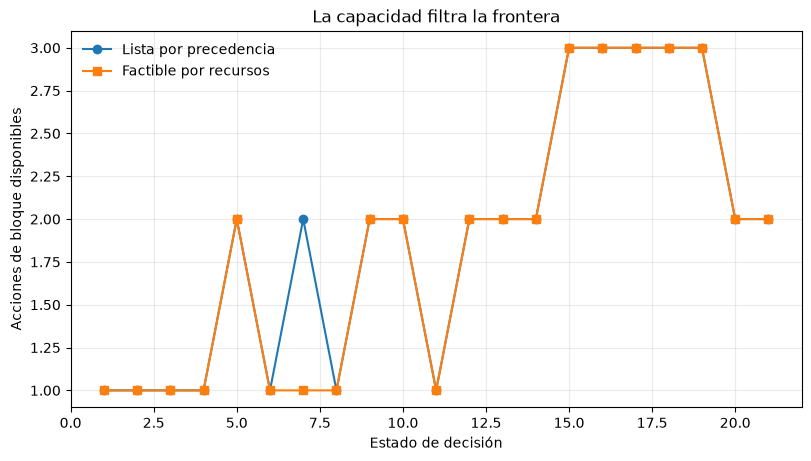

In [7]:
# Grafica cómo se reduce el conjunto de acciones factibles durante la reproducción.
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
steps = np.arange(1, len(ready_counts) + 1)
ax.plot(steps, ready_counts, marker="o", label="Lista por precedencia")
ax.plot(steps, feasible_counts, marker="s", label="Factible por recursos")
ax.set(
    xlabel="Estado de decisión",
    ylabel="Acciones de bloque disponibles",
    title="La capacidad filtra la frontera",
)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.show()


Sigue el mismo estado con ambas dimensiones de recursos separadas. Las líneas se derivan del plan y de su matriz de capacidad original. Una carga bajo su límite muestra capacidad sin usar en ese período; no indica si otro período o el grafo de precedencia impidió más trabajo. Lee ambos paneles junto con la razón de detención y los valores de cobertura impresos arriba.

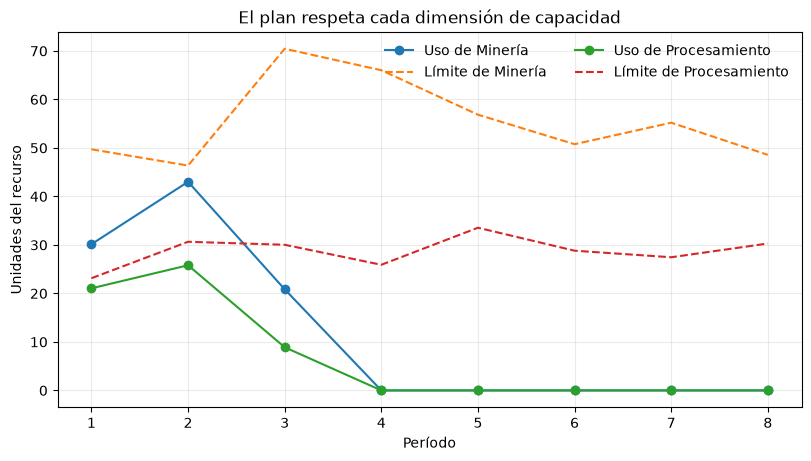

In [8]:
# Compara cada carga de recursos con su propia capacidad por período.
usage = np.zeros_like(instance.capacities)
for assignment in result.assignments:
    usage[assignment.period] += instance.resources[assignment.block]
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
periods = np.arange(1, len(instance.capacities) + 1)
for resource, name in enumerate(("Minería", "Procesamiento")):
    ax.plot(periods, usage[:, resource], marker="o", label=f"Uso de {name}")
    ax.plot(periods, instance.capacities[:, resource], linestyle="--", label=f"Límite de {name}")
ax.set(xlabel="Período", ylabel="Unidades del recurso", title="El plan respeta cada dimensión de capacidad")
ax.grid(alpha=0.25)
ax.legend(frameon=False, ncol=2)
plt.show()


El barrido conserva valores, aristas, variables y puntuación transparente. La cobertura no cambia con estos cuatro multiplicadores, mientras el NPV descontado varía según el período de los bloques. La respuesta pertenece solo a esta instancia generada. Interpreta ambos paneles como diagnóstico local, no como resultado entre casos.

{'factors': [0.7, 0.85, 1.0, 1.15], 'coverage_npv': [(0.19394082509847316, 6.260983374702888), (0.19394082509847316, 6.402517817175093), (0.19394082509847316, 6.5810534023261145), (0.19394082509847316, 6.5393945154820035)]}


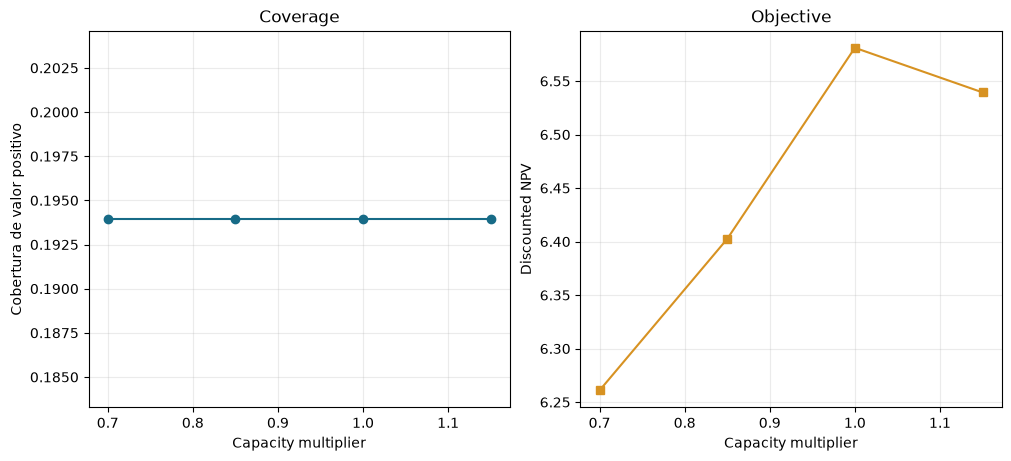

In [9]:
# Reproduce la misma puntuación con varios límites uniformes de capacidad.
from dataclasses import replace

factors = np.array([0.70, 0.85, 1.00, 1.15])
sweep = []
for factor in factors:
    variant = replace(instance, capacities=instance.capacities * factor)
    replay = replay_frontier_policy(variant, score, tonnage=case.tonnage)
    sweep.append((replay.positive_value_coverage, replay.npv))
print({"factors": factors.tolist(), "coverage_npv": sweep})
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
axes[0].plot(factors, [row[0] for row in sweep], marker="o", color="#176B87")
axes[0].set(xlabel="Capacity multiplier", ylabel="Cobertura de valor positivo", title="Coverage")
axes[1].plot(factors, [row[1] for row in sweep], marker="s", color="#D79222")
axes[1].set(xlabel="Capacity multiplier", ylabel="Discounted NPV", title="Objective")
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()


Lee esta curva como la respuesta de un grafo sintético fijo y una puntuación a los multiplicadores declarados. Muestra cómo cambia la cobertura de valor positivo en este ejemplo; no compara políticas ni estima comportamiento entre yacimientos. La tabla impresa también conserva el objetivo porque el valor descontado puede cambiar de forma distinta a la cobertura.

## Resultados

Interpreta el tamaño de la máscara como la cantidad de acciones que la política puede elegir legalmente en ese estado, no como una puntuación. Interpreta el objetivo junto con la cobertura: un plan parcial factible puede dejar bloques de valor positivo y toneladas sin asignar. El validador recalcula unicidad, precedencia, cada dimensión de capacidad y valor descontado desde la instancia original, así que una máscara válida anterior no excusa una exportación alterada. Este es el recorrido completo de la mecánica del método. Las afirmaciones empíricas corresponden a una evaluación congelada por separado; la lección de evidencia explica por qué el diagnóstico actual no puede cumplir ese papel.

**Respuesta:** El ejemplo de 96-block graph respalda los cálculos presentados, y su estado solo de validación limita la conclusión.

## Resumen

El límite del método es claro: la estructura del grafo y el estado parcial informan las puntuaciones, la máscara de factibilidad restringe las elecciones y un validador independiente comprueba el resultado exportado. El normalizador de entrenamiento tiene un hash para que la inferencia use exactamente el mismo orden y escala de variables. Al adaptar la canalización, conserva identificadores canónicos, unidades de origen, procedencia de particiones, razones de detención y ambas medidas de cobertura. No atribuyas una frontera vacía al modelo antes de revisar precedencias y cada recurso residual. Esta lección da un ejemplo auditable de mecánica, no una comparación ni recomendación de despliegue.

### Sensibilidad y límites

El barrido anterior varía toda la matriz de capacidades mediante un multiplicador declarado. Es una comprobación local de sensibilidad, no un estudio de robustez. Para identificar qué recurso afecta una decisión, varía por separado las columnas de minería y procesamiento, manteniendo las demás fijas; luego repite con una pequeña grilla factorial para detectar interacciones. Conserva la instancia original y crea una variante inmutable por ejecución. Registra el multiplicador, las columnas modificadas, la razón de detención, el objetivo, ambas coberturas y el resultado del validador en una tabla por caso. Grafica cada salida frente al parámetro y conserva los casos sin acciones. Si una métrica cambia abruptamente, inspecciona la traza alrededor del umbral: la precedencia puede hacer que un cambio pequeño de recursos libere una cadena de bloques.

Repite el ejercicio con varias familias y tamaños de grafo antes de describir un patrón. Usa el mismo conjunto de semillas para comparaciones pareadas y separa las semillas usadas para ajustar una política de las usadas para resumir su comportamiento. Informa la distribución completa y la cantidad de casos intentados, incluidas generaciones fallidas y rechazos del validador. Un solo grafo no estima incertidumbre ni demuestra estabilidad. El grafo de esta lección es sintético y la puntuación determinista es una sonda didáctica. Ni el barrido ni el validador miden realismo geológico, costos operacionales, confianza de reservas o aceptabilidad del plan. Esas preguntas requieren datos del dominio, un modelo económico aprobado y revisión independiente.

Para una tabla diagnóstica útil, conserva una fila por cada combinación de grafo, variante de recursos y configuración de política. Guarda el vector de capacidades original junto al multiplicador para que otro analista pueda reconstruir el experimento. Compara trazas para identificar la primera decisión divergente; las diferencias agregadas de objetivo pueden ocultar un cambio de período o un requisito limitante. Prueba el validador con planes alterados deliberadamente, incluidos bloques duplicados, precedencia invertida y asignaciones sobre capacidad, y confirma que informe cada infracción. Son verificaciones de software, no evidencia de generalización. Mantén los casos de desarrollo separados de cualquier evaluación congelada posterior y registra los cambios de protocolo antes de inspeccionar sus resultados.

### Uso con datos propios

Comienza con un contrato de entrada versionado. Mantén un identificador estable por bloque; declara unidades de valor, tonelaje, capacidad minera, capacidad de procesamiento y período de descuento; y conserva la procedencia de cada campo fuente. Valida valores finitos, consumos no negativos, identificadores únicos, aristas acíclicas y filas completas de capacidad antes de construir el grafo. Resuelve duplicados y datos faltantes mediante reglas documentadas, no imputaciones silenciosas. Evita variables derivadas de resultados y etiquetas económicas como entradas, y conserva el vínculo con registros fuente en un entorno controlado.

Construye particiones por yacimiento u otra agrupación geológica independiente cuando corresponda al uso esperado. Congela el manifiesto antes de seleccionar el modelo, ajusta el escalado solo con entrenamiento y reutiliza orden y hash de variables durante la inferencia. Ejecuta una línea base transparente sobre los mismos casos y conserva resultados pareados. Por política, persiste hash de entrada, configuración, semilla, checkpoint elegido, traza de acciones, razón de detención, hallazgos del validador, objetivo y ambas coberturas. Escribe cada caso de forma atómica para reanudar una evaluación interrumpida sin repetir los casos terminados. Solicita revisión independiente del validador y de las conversiones de unidades antes de usar resultados en una decisión real de planificación.

## Referencias

El objetivo de gradiente de política recortado da contexto al algoritmo de entrenamiento; el repositorio de PhaseFlow documenta su contrato de acciones, preprocesamiento y validador. Estas fuentes no trasladan afirmaciones de desempeño al ejemplo sintético. Cada valor numérico se calcula al ejecutar el cuaderno.

- Método de gradiente de política: https://arxiv.org/abs/1707.06347
- Optimizador adaptativo: https://arxiv.org/abs/1412.6980
- Formulación de planificación a cielo abierto: https://doi.org/10.1287/inte.2013.0731
- Implementación y registros: https://github.com/fsantibanezleal/CAOS_PhaseFlow